# 03 — Q2: Dự đoán điểm chất lượng trước khi cupping (ML)

**Người phụ trách:** Ngọc Hoàng · **Yêu cầu ML 1–3** · Nguồn: `docs/questions.md`

> Notebook này chỉ gồm phần **dựng khung**: định nghĩa bài toán, chặn rò rỉ dữ liệu, chia dữ liệu theo thời gian, Pipeline và cross-validation trên train. **Chưa** tinh chỉnh tham số và **không** đánh giá trên tập test.

<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 0</span>

## <span style="color:#ffffff">Môi trường code &amp; thư viện</span>

<span style="font-size:15px;color:#DCE6F7">Kiểm tra kernel và phiên bản thư viện khớp với <b>environment.yml</b></span>

</div>

In [1]:
import sys
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NOTEBOOK_CWD = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_CWD.parent if NOTEBOOK_CWD.name == "notebooks" else NOTEBOOK_CWD
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.config import RANDOM_STATE, SCORE_COLS
from src.cleaning import load_raw, convert_types, flag_placeholders
from src.features import add_total_score, add_grading_date
from src.labels import normalize_labels

pd.set_option("display.max_columns", None)

%matplotlib inline

print("python      :", sys.executable)
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("matplotlib  :", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)

python      : /home/hoang/miniconda3/envs/coffee/bin/python
numpy       : 1.26.4
pandas      : 2.1.4
matplotlib  : 3.8.4
scikit-learn: 1.9.1


<span style="color:#5B6B8C;font-size:14px">→ Mong đợi: đường dẫn kết thúc bằng <code>.../envs/coffee/bin/python</code></span>

In [2]:
# TEST
def major_minor(version):
    """'2.1.1' -> '2.1'"""
    return ".".join(version.split(".")[:2])

assert major_minor(np.__version__) == "1.26", f"numpy {np.__version__} khác environment.yml"
assert major_minor(pd.__version__) == "2.1", f"pandas {pd.__version__} khác environment.yml"
assert major_minor(matplotlib.__version__) == "3.8", f"matplotlib {matplotlib.__version__} khác environment.yml"
assert major_minor(sklearn.__version__) == "1.9", f"scikit-learn {sklearn.__version__} khác environment.yml"
print("Môi trường OK")

Môi trường OK


<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 1</span>

## <span style="color:#ffffff">Problem definition</span>

<span style="font-size:15px;color:#DCE6F7">Câu hỏi, đối tượng sử dụng, làm sạch theo phạm vi chung và chặn rò rỉ dữ liệu</span>

</div>

### <span style="color:#283E75">▍Câu hỏi Q2 (trích nguyên văn <code>docs/questions.md</code>)</span>

**Câu hỏi:** Khi nhận mẫu cà phê nhân xanh, chỉ dựa trên thông tin có sẵn **trước khi cupping** (xuất xứ, giống, phương pháp sơ chế, màu hạt, độ ẩm, số lỗi hạt, năm thu hoạch), mô hình dự đoán `total_9` sai lệch trung bình bao nhiêu điểm, có tốt hơn đáng kể so với việc chỉ đoán điểm trung bình không, và thông tin nào giúp dự đoán nhiều nhất?

- **Motivation:** nhà nhập khẩu nhận nhiều mẫu nhưng cupping tốn thời gian và chi phí; điểm dự đoán giúp **ưu tiên lô nào gửi đi chấm trước** và ước lượng sơ bộ chất lượng khi đàm phán.

✍️ **TODO (Hoàng tự viết):** ai dùng, lúc nào, quyết định gì

### <span style="color:#283E75">▍Đọc và làm sạch theo phạm vi chung</span>

1. Đọc dữ liệu → `convert_types` → `normalize_labels` → `add_total_score` → `add_grading_date`.
2. Chỉ giữ Arabica.
3. Bỏ bản ghi giữ chỗ `flag_placeholders(...)["zero_all_scores"]` (`REC_ID = 1310`).
4. Bỏ dòng thiếu `total_9`.
5. Thay `Moisture = 0` bằng NaN (không bỏ dòng; Pipeline sẽ điền thiếu, chỉ học từ train).

In [3]:
TARGET = "total_9"
SPLIT_DATE = pd.Timestamp("2016-01-01")

row_counts = {}   # Bước -> số lô còn lại

df = add_grading_date(add_total_score(normalize_labels(convert_types(load_raw()))))
row_counts["1. Dữ liệu gốc (load → convert → normalize → total_9 → grading_date)"] = len(df)
print(f"Số lô: {len(df):,} · số cột: {df.shape[1]}")

Số lô: 1,339 · số cột: 24


<span style="color:#5B6B8C;font-size:14px"><code>normalize_labels</code> đưa nhãn về chữ thường → in nhãn thực tế trước khi lọc.</span>

In [4]:
print(df["Species"].value_counts(dropna=False))

Species
arabica    1311
robusta      28
Name: count, dtype: Int64


In [5]:
ARABICA = "arabica"   # đúng chuỗi in ra ở ô trên
assert ARABICA in set(df["Species"].dropna()), f"Không tìm thấy nhãn {ARABICA!r} trong Species"

df_ml = df[df["Species"].eq(ARABICA)].copy()
row_counts["2. Chỉ giữ Arabica"] = len(df_ml)

placeholder = flag_placeholders(df_ml)["zero_all_scores"]
print("REC_ID bị đánh dấu zero_all_scores:", df_ml.loc[placeholder, "REC_ID"].tolist())
df_ml = df_ml[~placeholder].copy()
row_counts["3. Bỏ bản ghi giữ chỗ (zero_all_scores)"] = len(df_ml)

print("Số dòng thiếu total_9:", df_ml[TARGET].isna().sum())
df_ml = df_ml.dropna(subset=[TARGET]).copy()
row_counts["4. Bỏ dòng thiếu total_9"] = len(df_ml)

n_zero_moisture = int(df_ml["Moisture"].eq(0).sum())
df_ml["Moisture"] = df_ml["Moisture"].mask(df_ml["Moisture"].eq(0))
row_counts["5. Moisture = 0 → NaN (không lọc)"] = len(df_ml)
print(f"Số lô Moisture = 0 đổi thành NaN: {n_zero_moisture}")

clean_steps = pd.DataFrame(list(row_counts.items()), columns=["Bước", "Số lô"])
display(clean_steps)

REC_ID bị đánh dấu zero_all_scores: [1310]
Số dòng thiếu total_9: 0
Số lô Moisture = 0 đổi thành NaN: 252


,Bước,Số lô
0,1. Dữ liệu gốc (load → convert → normalize → t...,1339
1,2. Chỉ giữ Arabica,1311
2,3. Bỏ bản ghi giữ chỗ (zero_all_scores),1310
3,4. Bỏ dòng thiếu total_9,1310
4,5. Moisture = 0 → NaN (không lọc),1310


### <span style="color:#283E75">▍Feature được dùng</span>

<span style="color:#5B6B8C;font-size:14px">Chỉ gồm thông tin có trước khi cupping. Thống kê dưới đây chỉ để mô tả, <b>không</b> dùng để biến đổi dữ liệu.</span>

In [6]:
NUM_FEATURES = ["Moisture", "Quakers", "Category.One.Defects", "Category.Two.Defects", "Harvest.Year"]
CAT_FEATURES = ["Country.of.Origin", "Continent.of.Origin", "Variety", "Processing.Method", "Color"]
FEATURES = CAT_FEATURES + NUM_FEATURES

feature_table = pd.DataFrame({
    "Cột": FEATURES,
    "Kiểu": ["phân loại" if c in CAT_FEATURES else "số" for c in FEATURES],
    "Số giá trị thiếu": [int(df_ml[c].isna().sum()) for c in FEATURES],
    "% thiếu": [round(df_ml[c].isna().mean() * 100, 1) for c in FEATURES],
    "Số giá trị khác nhau": [int(df_ml[c].nunique(dropna=True)) for c in FEATURES],
})
display(feature_table)

,Cột,Kiểu,Số giá trị thiếu,% thiếu,Số giá trị khác nhau
0,Country.of.Origin,phân loại,1,0.1,34
1,Continent.of.Origin,phân loại,1,0.1,5
2,Variety,phân loại,201,15.3,29
3,Processing.Method,phân loại,151,11.5,5
4,Color,phân loại,216,16.5,4
5,Moisture,số,252,19.2,22
6,Quakers,số,0,0.0,11
7,Category.One.Defects,số,0,0.0,16
8,Category.Two.Defects,số,0,0.0,38
9,Harvest.Year,số,60,4.6,10


<span style="color:#5B6B8C;font-size:14px">Số nhóm có &lt; 20 lô ở mỗi cột phân loại (trên toàn mẫu sạch, chỉ để mô tả; việc gộp nhóm hiếm thực sự do <code>OneHotEncoder(min_frequency=20)</code> học trên train).</span>

In [7]:
rare_table = pd.DataFrame({
    "Cột": CAT_FEATURES,
    "Số nhóm": [df_ml[c].nunique() for c in CAT_FEATURES],
    "Số nhóm < 20 lô": [int(df_ml[c].value_counts().lt(20).sum()) for c in CAT_FEATURES],
    "Số lô thuộc nhóm < 20 lô": [
        int(df_ml[c].value_counts().loc[lambda s: s.lt(20)].sum()) for c in CAT_FEATURES
    ],
})
display(rare_table)

,Cột,Số nhóm,Số nhóm < 20 lô,Số lô thuộc nhóm < 20 lô
0,Country.of.Origin,34,18,80
1,Continent.of.Origin,5,1,1
2,Variety,29,20,103
3,Processing.Method,5,1,14
4,Color,4,0,0


### <span style="color:#283E75">▍Cột bị loại và lý do</span>

In [8]:
DROPPED = (
    [(c, "Thuộc tính cảm quan; 9 cột cộng lại chính là total_9") for c in SCORE_COLS]
    + [
        (TARGET, "Biến mục tiêu"),
        ("REC_ID", "Định danh bản ghi"),
        ("Expiration", "Chỉ biết sau khi chấm; chỉ dùng để chia dữ liệu"),
        ("grading_date", "Suy ra từ Expiration; chỉ dùng để chia dữ liệu"),
        ("Species", "Đã lọc chỉ còn một giá trị (arabica)"),
    ]
)
DROPPED_COLS = [c for c, _ in DROPPED]
dropped_table = pd.DataFrame(DROPPED, columns=["Cột", "Lý do loại"])
display(dropped_table)

unaccounted = sorted(set(df_ml.columns) - set(FEATURES) - set(DROPPED_COLS))
assert not unaccounted, f"Có cột chưa được xếp vào feature hay cột bị loại: {unaccounted}"
assert not set(FEATURES) & set(DROPPED_COLS), "Một cột vừa là feature vừa bị loại"

,Cột,Lý do loại
0,Aroma,Thuộc tính cảm quan; 9 cột cộng lại chính là t...
1,Flavor,Thuộc tính cảm quan; 9 cột cộng lại chính là t...
2,Aftertaste,Thuộc tính cảm quan; 9 cột cộng lại chính là t...
3,Acidity,Thuộc tính cảm quan; 9 cột cộng lại chính là t...
4,Body,Thuộc tính cảm quan; 9 cột cộng lại chính là t...
5,Balance,Thuộc tính cảm quan; 9 cột cộng lại chính là t...
6,Uniformity,Thuộc tính cảm quan; 9 cột cộng lại chính là t...
7,Clean.Cup,Thuộc tính cảm quan; 9 cột cộng lại chính là t...
8,Sweetness,Thuộc tính cảm quan; 9 cột cộng lại chính là t...
9,total_9,Biến mục tiêu


✍️ **TODO (Hoàng tự viết):** giải thích vì sao các cột trên gây rò rỉ dữ liệu

<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 2</span>

## <span style="color:#ffffff">Split theo thời gian</span>

<span style="font-size:15px;color:#DCE6F7">Train = lô chấm trước 2016-01-01, test = từ mốc trở đi</span>

</div>

In [9]:
df_ml = df_ml.sort_values(["grading_date", "REC_ID"], kind="mergesort").reset_index(drop=True)
assert df_ml["grading_date"].notna().all(), "Có lô thiếu grading_date"

is_train = df_ml["grading_date"].lt(SPLIT_DATE)
train_df = df_ml[is_train].copy()
test_df = df_ml[~is_train].copy()


def describe_set(name, part):
    return {
        "Tập": name,
        "Số lô": len(part),
        "Ngày chấm sớm nhất": part["grading_date"].min().date(),
        "Ngày chấm muộn nhất": part["grading_date"].max().date(),
        "Mean total_9": part[TARGET].mean(),
        "Std total_9": part[TARGET].std(),
        "Median total_9": part[TARGET].median(),
    }


split_table = pd.DataFrame([describe_set("Train", train_df), describe_set("Test", test_df)])
display(split_table.round(2))

,Tập,Số lô,Ngày chấm sớm nhất,Ngày chấm muộn nhất,Mean total_9,Std total_9,Median total_9
0,Train,1041,2010-04-09,2015-12-28,74.60,2.47,74.92
1,Test,269,2016-01-12,2018-01-19,74.96,1.98,75.25


#### <span style="color:#3B5BA9">Kiểm tra cặp trùng <code>REC_ID</code> 721 / 742</span>

In [10]:
pair = df_ml.loc[df_ml["REC_ID"].isin([721, 742]), ["REC_ID", "grading_date"]].assign(
    Tập=lambda d: np.where(d["grading_date"].lt(SPLIT_DATE), "Train", "Test")
)
display(pair)
assert len(pair) == 2, f"Phải có đủ 2 bản ghi 721 / 742, đang có {len(pair)}"
assert pair["Tập"].nunique() == 1, "REC_ID 721 và 742 rơi vào 2 tập khác nhau — DỪNG LẠI và báo nhóm"
print("721 / 742 cùng nằm trong tập:", pair["Tập"].iloc[0])

,REC_ID,grading_date,Tập
579,721,2013-12-26,Train
580,742,2013-12-26,Train


721 / 742 cùng nằm trong tập: Train


> ⚠️ **Tập test chỉ được đánh giá một lần ở tuần 3.** Sau ô dưới đây, không ô nào trong notebook này được đọc `X_test` / `y_test`.

In [11]:
# Tách X / y. X chỉ gồm FEATURES; đổi kiểu (không học gì từ dữ liệu) để sklearn xử lý NaN thống nhất:
#   cột phân loại: pandas string (pd.NA) → object (np.nan); cột số: Int64 → float.
def to_model_frame(part):
    X = part[FEATURES].copy()
    for c in CAT_FEATURES:
        X[c] = X[c].astype(object).where(X[c].notna(), np.nan)
    for c in NUM_FEATURES:
        X[c] = pd.to_numeric(X[c], errors="coerce").astype(float)
    return X


X_train, y_train = to_model_frame(train_df), train_df[TARGET].to_numpy()
X_test, y_test = to_model_frame(test_df), test_df[TARGET].to_numpy()   # cất đi, chỉ dùng ở tuần 3
print(f"X_train: {X_train.shape} · X_test: {X_test.shape}")

X_train: (1041, 10) · X_test: (269, 10)


#### <span style="color:#3B5BA9">Số lô train / test theo năm chấm</span>

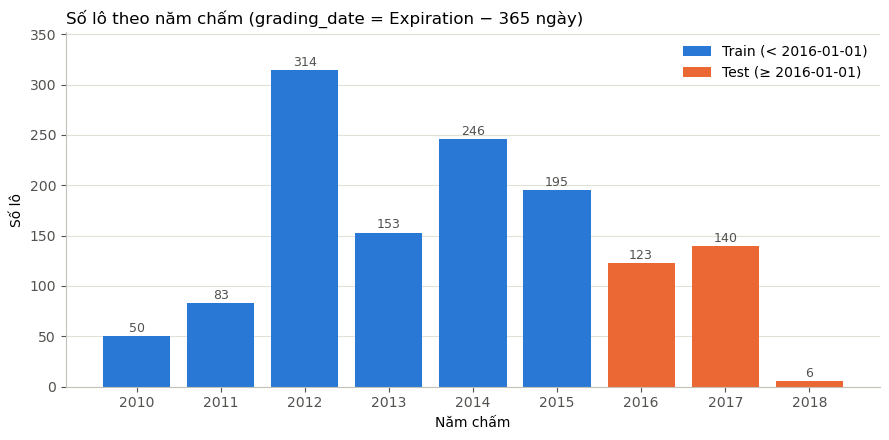

In [12]:
COLOR_TRAIN = "#2a78d6"
COLOR_TEST = "#eb6834"
INK_SECONDARY = "#52514e"
GRID_COLOR = "#e1e0d9"


def style_axes(ax, grid_axis="y"):
    """Lưới mảnh, bỏ viền trên/phải."""
    ax.grid(axis=grid_axis, color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c3c2b7")
    ax.tick_params(colors=INK_SECONDARY)


year_counts = (
    df_ml.assign(Năm=df_ml["grading_date"].dt.year,
                 Tập=np.where(is_train, "Train", "Test"))
    .groupby(["Năm", "Tập"]).size().unstack("Tập", fill_value=0)
    .reindex(columns=["Train", "Test"], fill_value=0)
)

fig, ax = plt.subplots(figsize=(9, 4.5))
years = year_counts.index.astype(str)
ax.bar(years, year_counts["Train"], color=COLOR_TRAIN, label=f"Train (< {SPLIT_DATE.date()})")
ax.bar(years, year_counts["Test"], bottom=year_counts["Train"], color=COLOR_TEST,
       label=f"Test (≥ {SPLIT_DATE.date()})")
for x, total in zip(years, year_counts.sum(axis=1)):
    ax.annotate(f"{total}", (x, total), xytext=(0, 3), textcoords="offset points",
                ha="center", fontsize=9, color=INK_SECONDARY)
ax.set_ylim(0, year_counts.sum(axis=1).max() * 1.12)
ax.set_title("Số lô theo năm chấm (grading_date = Expiration − 365 ngày)", loc="left", fontsize=12)
ax.set_xlabel("Năm chấm")
ax.set_ylabel("Số lô")
ax.legend(frameon=False)
style_axes(ax, grid_axis="y")
fig.tight_layout()
plt.show()

✍️ **TODO (Hoàng tự viết):** vì sao chia theo thời gian thay vì ngẫu nhiên

<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 3</span>

## <span style="color:#ffffff">Pipeline, baseline và 2 mô hình</span>

<span style="font-size:15px;color:#DCE6F7">Mọi bước học từ dữ liệu nằm trong Pipeline · cross-validation chỉ trên train</span>

</div>

### <span style="color:#283E75">▍Tiền xử lý trong <code>ColumnTransformer</code></span>

In [13]:
def make_preprocessor():
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="unknown")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20)),
    ])
    return ColumnTransformer([
        ("num", numeric, NUM_FEATURES),
        ("cat", categorical, CAT_FEATURES),
    ])


MODELS = {
    "Baseline (Dummy mean)": DummyRegressor(strategy="mean"),
    "Ridge (alpha=1.0)": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
}
pipelines = {name: Pipeline([("pre", make_preprocessor()), ("reg", model)])
             for name, model in MODELS.items()}
pipelines["Ridge (alpha=1.0)"]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of 

### <span style="color:#283E75">▍Cross-validation <code>TimeSeriesSplit(n_splits=5)</code> trên train</span>

<span style="color:#5B6B8C;font-size:14px"><code>X_train</code> đã sắp theo <code>grading_date</code> nên mỗi fold validation luôn nằm sau phần dữ liệu dùng để fit. MAE/RMSE đơn vị điểm <code>total_9</code>; sklearn trả về giá trị âm nên đổi dấu khi báo cáo.</span>

In [14]:
tscv = TimeSeriesSplit(n_splits=5)
SCORING = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"}

cv_results = {}
for name, pipe in pipelines.items():
    res = cross_validate(pipe, X_train, y_train, cv=tscv, scoring=SCORING)
    cv_results[name] = {"MAE": -res["test_MAE"], "RMSE": -res["test_RMSE"]}

fold_sizes = pd.DataFrame(
    [{"Fold": k + 1, "Số lô fit": len(tr), "Số lô validation": len(va),
      "Validation từ": train_df["grading_date"].iloc[va[0]].date(),
      "Validation đến": train_df["grading_date"].iloc[va[-1]].date()}
     for k, (tr, va) in enumerate(tscv.split(X_train))]
)
display(fold_sizes)

,Fold,Số lô fit,Số lô validation,Validation từ,Validation đến
0,1,176,173,2012-02-23,2012-08-30
1,2,349,173,2012-08-30,2013-05-30
2,3,522,173,2013-05-30,2014-05-05
3,4,695,173,2014-05-05,2015-02-13
4,5,868,173,2015-02-15,2015-12-28


In [15]:
baseline_mae = cv_results["Baseline (Dummy mean)"]["MAE"].mean()
cv_table = pd.DataFrame([
    {
        "Mô hình": name,
        "MAE (điểm)": f"{r['MAE'].mean():.3f} ± {r['MAE'].std():.3f}",
        "RMSE (điểm)": f"{r['RMSE'].mean():.3f} ± {r['RMSE'].std():.3f}",
        "MAE so với baseline (điểm)": round(r["MAE"].mean() - baseline_mae, 3),
        "MAE so với baseline (%)": round((r["MAE"].mean() / baseline_mae - 1) * 100, 1),
    }
    for name, r in cv_results.items()
])
display(cv_table)

,Mô hình,MAE (điểm),RMSE (điểm),MAE so với baseline (điểm),MAE so với baseline (%)
0,Baseline (Dummy mean),1.654 ± 0.118,2.524 ± 0.306,0.000,0.0
1,Ridge (alpha=1.0),1.772 ± 0.140,2.432 ± 0.248,0.118,7.1
2,Random Forest,1.725 ± 0.125,2.527 ± 0.251,0.070,4.2


<span style="color:#5B6B8C;font-size:14px">± là độ lệch chuẩn qua 5 fold. Cột “so với baseline” &lt; 0 nghĩa là sai số nhỏ hơn baseline.</span>

#### <span style="color:#3B5BA9">MAE từng fold</span>

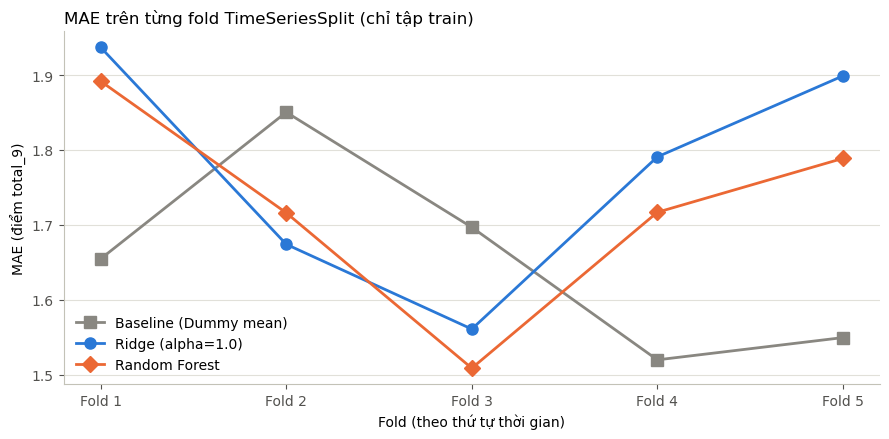

In [16]:
MODEL_COLORS = {
    "Baseline (Dummy mean)": "#898781",
    "Ridge (alpha=1.0)": "#2a78d6",
    "Random Forest": "#eb6834",
}
MODEL_MARKERS = {"Baseline (Dummy mean)": "s", "Ridge (alpha=1.0)": "o", "Random Forest": "D"}

fig, ax = plt.subplots(figsize=(9, 4.5))
folds = np.arange(1, tscv.get_n_splits() + 1)
for name, r in cv_results.items():
    ax.plot(folds, r["MAE"], marker=MODEL_MARKERS[name], markersize=8, linewidth=2,
            color=MODEL_COLORS[name], label=name)
ax.set_xticks(folds)
ax.set_xticklabels([f"Fold {k}" for k in folds])
ax.set_title("MAE trên từng fold TimeSeriesSplit (chỉ tập train)", loc="left", fontsize=12)
ax.set_xlabel("Fold (theo thứ tự thời gian)")
ax.set_ylabel("MAE (điểm total_9)")
ax.legend(frameon=False)
style_axes(ax, grid_axis="y")
fig.tight_layout()
plt.show()

✍️ **TODO (Hoàng tự viết):** nhận xét CV — mô hình nào hơn baseline, hơn bao nhiêu điểm

### <span style="color:#283E75">▍Kiểm tra</span>

<span style="color:#5B6B8C;font-size:14px">Cách đảm bảo <code>X_test</code> / <code>y_test</code> không bị dùng: ô tách dữ liệu được gắn tag <code>test-split</code>; ô TEST đọc chính file notebook và kiểm tra không ô code nào <b>sau</b> ô đó chứa tên hai biến này (mẫu regex được viết để không tự khớp với chính nó).</span>

In [17]:
# TEST
# 1. Phạm vi chung, y không NaN
assert not df_ml["REC_ID"].eq(1310).any(), "REC_ID 1310 vẫn còn"
assert df_ml["Species"].eq(ARABICA).all(), "Còn loài khác Arabica"
assert not np.isnan(y_train).any(), "y_train có NaN"
assert df_ml[TARGET].notna().all(), "total_9 có NaN"

# 2. Không cột bị loại nào trong X_train
leaked = sorted(set(X_train.columns) & set(DROPPED_COLS))
assert not leaked, f"Cột bị loại xuất hiện trong X_train: {leaked}"
assert list(X_train.columns) == FEATURES, "X_train phải đúng bằng danh sách FEATURES"

# 3. Mọi lô train chấm trước mọi lô test
assert train_df["grading_date"].max() < test_df["grading_date"].min(), "Train và test chồng lấn thời gian"
assert train_df["grading_date"].is_monotonic_increasing, "Train chưa sắp theo grading_date"

# 4. Train + test = số lô sau làm sạch
assert len(train_df) + len(test_df) == len(df_ml) == clean_steps["Số lô"].iloc[-1], (
    f"{len(train_df)} + {len(test_df)} ≠ {len(df_ml)}"
)

# 5. Pipeline fit được trên train, dự đoán đúng số dòng
for name, pipe in pipelines.items():
    pred = pipe.fit(X_train, y_train).predict(X_train)
    assert pred.shape == (len(X_train),), f"{name}: dự đoán {pred.shape} khác {len(X_train)} dòng"

# 6. Không ô code nào sau ô tách dữ liệu tham chiếu tập test
nb_path = PROJECT_ROOT / "notebooks" / "03_ml_question.ipynb"
nb_cells = json.loads(nb_path.read_text(encoding="utf-8"))["cells"]
split_idx = next(i for i, c in enumerate(nb_cells) if "test-split" in c["metadata"].get("tags", []))
forbidden = re.compile(r"\b[Xy]_test\b")
offenders = [i for i, c in enumerate(nb_cells[split_idx + 1:], split_idx + 1)
             if c["cell_type"] == "code" and forbidden.search("".join(c["source"]))]
assert not offenders, f"Ô {offenders} tham chiếu biến của tập test sau khi tách"

print("Q2 setup checks passed")

Q2 setup checks passed
